# 05 O 2020, uma única vez

O procedimento já está fixo: o notebook 04 escolheu o modelo só com 2013-2019. Aqui treino com 2013-2019 e avalio no 2020. Já tinha visto resultados de 2020 durante a exploração, por isso não é um teste cego. Nenhuma escolha usa o 2020, e não ajusto nada depois de o ver.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

sys.path.insert(0, "../task1/best_model")        # as funções que o train.py e o predict também usam
sys.path.insert(0, "../task1/training_code")
import utils, cv, selection

AZUL, VERM, VERDE = "#0072B2", "#D55E00", "#009E73"          # paleta Okabe-Ito, legível por daltónicos
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8.5, "axes.titleweight": "normal", "axes.titlelocation": "left",
    "figure.figsize": (3.4, 2.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.unicode_minus": False, "savefig.dpi": 200,
    "savefig.bbox": "tight", "legend.frameon": False,
})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def guardar(fig, nome):
    fig.savefig(FIG / f"{nome}.png")
    plt.show()

In [2]:
raw = pd.read_csv("../data/classification_task1_train.csv", parse_dates=["Date"])
comp = raw[(raw["Year"] < 2020) & raw["CHL"].notna()].copy()      # 2013-2019, só linhas completas
config = json.load(open("../task1/training_code/config.json"))      # escrito no notebook 04, só com 2013-2019
cands = selection.candidates()
final = config["candidato"]                                         # Logistic Regression, C=5, o modelo entregue
C = config["params"]["C"]
cands[final] = {"family": "Logistic Regression", "params": {"C": C},
                "fit_score": lambda tr, va: utils.score(utils.fit_logreg(tr, utils.DEFAULT_SPEC, C), va)}
outra = [c["candidato"] for f, c in config["melhor_por_familia"].items() if f != config["modelo_final"]][0]
print(f"modelo final: {final}\noutra família, só para contexto: {outra}")

modelo final: Logistic Regression, C=5
outra família, só para contexto: Extra Trees, leaf=5, features=sqrt, weights=none


## O resultado

In [3]:
c20 = raw[(raw["Year"] == 2020) & raw["CHL"].notna()].copy()       # só aqui o 2020 é usado, uma vez, com tudo já fixo
auc20 = {}
scores20 = {}
for nome in (final, outra):
    scores20[nome] = cands[nome]["fit_score"](comp, c20)             # treina em 2013-2019, prevê o 2020
    auc20[nome] = roc_auc_score(c20["HAB"], scores20[nome])
print(f"2020: {len(c20)} linhas completas, {c20['HAB'].sum()} eventos HAB")
pd.Series(auc20).round(3)

2020: 87 linhas completas, 21 eventos HAB


Logistic Regression, C=5                            0.864
Extra Trees, leaf=5, features=sqrt, weights=none    0.825
dtype: float64

In [4]:
def intervalo_por_datas(df, score, n=1000, semente=42):
    """Bootstrap em blocos: sorteia datas inteiras, porque as linhas da mesma data parecem-se."""
    rng = np.random.default_rng(semente)
    por_data = {d: i for d, i in df.groupby("Date").indices.items()}
    datas = list(por_data)
    y = df["HAB"].to_numpy()
    aucs = []
    for _ in range(n):
        idx = np.concatenate([por_data[datas[k]] for k in rng.integers(0, len(datas), len(datas))])
        if y[idx].min() != y[idx].max():
            aucs.append(roc_auc_score(y[idx], score[idx]))
    return np.percentile(aucs, [2.5, 97.5])

inf, sup = intervalo_por_datas(c20, scores20[final])
print(f"{final}: AUC {auc20[final]:.3f} em 2020, intervalo de 95% [{inf:.3f}, {sup:.3f}]")

Logistic Regression, C=5: AUC 0.864 em 2020, intervalo de 95% [0.772, 0.935]


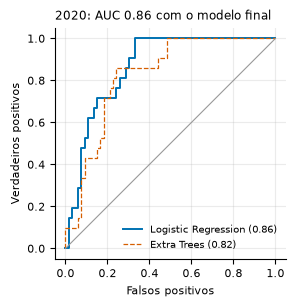

In [5]:
fig, ax = plt.subplots(figsize=(3.2, 3.0))
for nome, cor, estilo in [(final, AZUL, "-"), (outra, VERM, "--")]:
    fpr, tpr, _ = roc_curve(c20["HAB"], scores20[nome])
    ax.plot(fpr, tpr, estilo, color=cor, lw=1.4 if nome == final else 0.9, label=f"{cands[nome]['family']} ({auc20[nome]:.2f})")
ax.plot([0, 1], [0, 1], color="#999999", lw=0.8)
ax.set(xlabel="Falsos positivos", ylabel="Verdadeiros positivos", aspect="equal", title=f"2020: AUC {auc20[final]:.2f} com o modelo final")
ax.legend(loc="lower right", fontsize=7); guardar(fig, "15_roc_2020")

Em 2020 a Logistic Regression (C = 5) dá 0.864, com um intervalo de 95% de 0.772 a 0.935 (bootstrap que sorteia datas inteiras). O Extra Trees dá 0.825. São 21 eventos em 87 linhas, por isso o intervalo é largo e a diferença entre os dois modelos não quer dizer nada sozinha. O 2020 dá um AUC mais alto do que a média de 2013-2019 (0.789 no nested), o que é coerente com o desvio entre anos de cerca de 0.08.

## Todos os modelos treinados

Comparo, com a mesma leave-one-year-out de 2013-2019, os modelos que treinei no projeto, e junto o 2020 (training 2013-2019, visto só aqui).
A tabela tem o AUC de cada ano, a média por ano, o agrupado e o 2020.
A figura mostra a curva ROC de cada modelo com as previsões de todos os anos juntas (fora-de-fold), e na legenda o AUC por ano com o desvio entre anos.
A Logistic Regression e o Extra Trees vêm do notebook 04.
Os outros usam hiperparâmetros fixos da exploração e não foram afinados numa nested cross-validation, por isso a comparação com eles é menos apertada.

In [6]:
import all_models

tab, oofs = all_models.compare(comp, c20)            # todos os modelos, leave-one-year-out em 2013-2019 e o 2020
anos = [c for c in tab.columns if isinstance(c, int)]
tab.round(3)

,2013,2015,2016,2018,2019,media,agrupado,2020
só sazonalidade,0.512,0.637,0.776,0.848,0.704,0.695,0.709,0.754
só ambientais,0.502,0.787,0.601,0.769,0.554,0.643,0.609,0.612
sazonalidade + cluster,0.649,0.693,0.821,0.898,0.826,0.777,0.804,0.853
"Logistic Regression, C=0.01",0.599,0.840,0.835,0.892,0.739,0.781,0.780,0.798
"Logistic Regression, C=0.1",0.637,0.773,0.853,0.906,0.765,0.787,0.794,0.846
"Logistic Regression, C=1",0.668,0.767,0.858,0.898,0.780,0.794,0.797,0.863
"Logistic Regression, C=5",0.673,0.773,0.857,0.899,0.786,0.798,0.796,0.864
"Logistic Regression, C=10",0.673,0.773,0.857,0.898,0.786,0.798,0.796,0.865
"Logistic Regression, C=100",0.673,0.773,0.857,0.898,0.787,0.798,0.796,0.864
Extra Trees,0.697,0.793,0.812,0.899,0.801,0.801,0.766,0.825


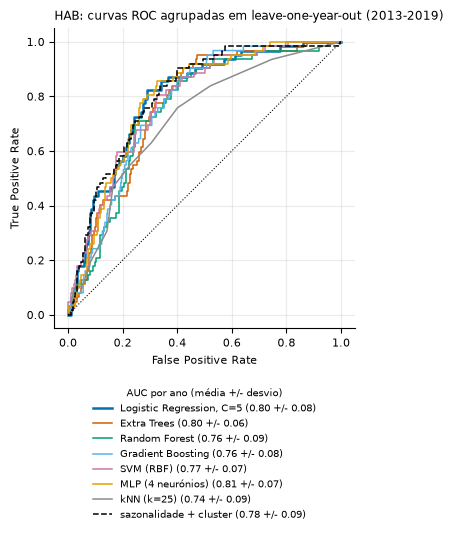

In [7]:
mostrar = {"Logistic Regression, C=5": (AZUL, 1.8), "Extra Trees": (VERM, 1.1), "Random Forest": ("#009E73", 1.1), "Gradient Boosting": ("#56B4E9", 1.1),
           "SVM (RBF)": ("#CC79A7", 1.1), "MLP (4 neurónios)": ("#E69F00", 1.1), "kNN (k=25)": ("#8C8C8C", 1.1), "sazonalidade + cluster": ("#000000", 1.1)}
fig, ax = plt.subplots(figsize=(4.4, 3.9))
for nome, (cor, lw) in mostrar.items():
    fpr, tpr, _ = roc_curve(comp["HAB"], oofs[nome])                   # previsões fora-de-fold de todos os anos juntas
    por_ano = tab.loc[nome, anos].astype(float)
    ax.plot(fpr, tpr, color=cor, lw=lw, ls="--" if nome.startswith("saz") else "-", label=f"{nome} ({por_ano.mean():.2f} +/- {np.std(por_ano):.2f})")
ax.plot([0, 1], [0, 1], "k:", lw=0.8)
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", aspect="equal", title="HAB: curvas ROC agrupadas em leave-one-year-out (2013-2019)")
ax.legend(title="AUC por ano (média +/- desvio)", loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=1, fontsize=7, title_fontsize=7)
guardar(fig, "16_roc_combinada")

O Extra Trees (0.801) e o MLP (0.808) ficam 0.003 a 0.010 acima da Logistic Regression com C = 5 (0.798) por ano, mas ficam abaixo no agrupado (0.766 e 0.792 contra 0.796) e em 2020 (0.825 e 0.840 contra 0.864). Estas diferenças são menores do que a variação entre anos, por isso é um empate, e o nested do notebook 04 já mostrou que é a escolha do Extra Trees que se perde nos anos de fora. O Random Forest, o Gradient Boosting, o SVM e o kNN ficam abaixo (0.735 a 0.774 por ano). Na Logistic Regression o AUC é plano a partir de C = 1 (0.794 a 0.798).

## Matrizes de confusão

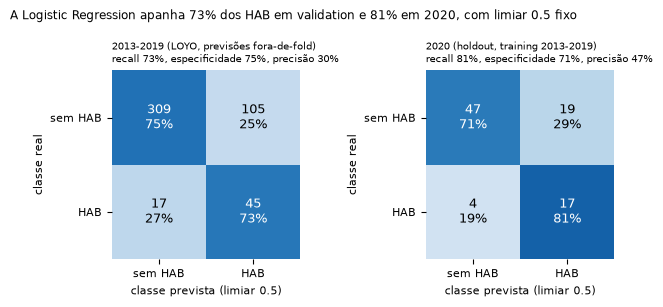

In [8]:
nome = "Logistic Regression, C=5"                    # o modelo final; limiar 0.5, o natural com class_weight balanced
conf = {"2013-2019 (LOYO, previsões fora-de-fold)": all_models.confusion(comp["HAB"], oofs[nome]),
        "2020 (holdout, training 2013-2019)": all_models.confusion(c20["HAB"], scores20[final])}
fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.0))
for ax, (titulo, c) in zip(axes, conf.items()):
    cm = c["cm"]; pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1); ax.grid(False); ax.spines[:].set_visible(False)
    for i, j in np.ndindex(2, 2):
        ax.text(j, i, f"{cm[i, j]}\n{pct[i, j]:.0%}", ha="center", va="center", fontsize=9, color="white" if pct[i, j] > 0.55 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["sem HAB", "HAB"], yticklabels=["sem HAB", "HAB"], xlabel="classe prevista (limiar 0.5)", ylabel="classe real")
    ax.set_title(f"{titulo}\nrecall {c['recall']:.0%}, especificidade {c['specificity']:.0%}, precisão {c['precision']:.0%}", fontsize=7.5)
r = [c["recall"] for c in conf.values()]
fig.suptitle(f"A Logistic Regression apanha {r[0]:.0%} dos HAB em validation e {r[1]:.0%} em 2020, com limiar 0.5 fixo", fontsize=8.5, x=0.01, ha="left", y=0.99)
fig.tight_layout(); guardar(fig, "17_matrizes_confusao")

Uso o limiar 0.5, o natural de um modelo treinado com class_weight balanced, e não o escolhi olhando para os resultados. Em 2013-2019 o modelo apanha 45 dos 62 HAB (recall 73%) e acerta 309 dos 414 sem HAB (especificidade 75%). Em 2020 apanha 17 dos 21 (81%) e acerta 47 de 66 (71%). A precisão é baixa (30% e 47%): como só 13% das linhas são HAB, 105 dos 150 alarmes em validation são falsos. Outro limiar muda esta troca entre recall e falsos alarmes, mas não muda o AUC.

## O que vai para o `train.py`

O `train.py` repete este procedimento: compara a Logistic Regression e o Extra Trees com nested leave-one-year-out em 2013-2019, fica com a família com melhor AUC nos anos de fora (a Logistic Regression), escolhe o C com leave-one-year-out em 2013-2019 (C = 5) e treina com todos os anos, 2013-2020 (563 linhas, 83 eventos).